# Flat integral stringers, simply supported and clamped: the Caltech shells AS-2 to AS-4 (Singer, Arbocz and Babcock 1971)

Singer, Arbocz and Babcock [1] tested in axial compression, besides
ring-stiffened shells, three aluminium shells with 80 integral stringers
machined on the outside, AS-2, AS-3 and AS-4. Their stringers are flat (3.5
to 6 times wider than tall), and the paper gives for them the buckling
loads of a linear smeared-stiffener theory for two end conditions: simple
support SS-3 ($w = v = N_x = M_x = 0$) and clamping C-4 ($w = v = u =
w_{,x} = 0$), the latter with a membrane pre-buckling state and with the
nonlinear pre-buckling deformation caused by the end rings (Table 2, p.
71). The authors judged the end rings of their test rig rigid enough to
consider the shells clamped (p. 72): clamping raises the load of these
shells by 23 to 48 %.

This notebook models the shells with discrete stringers (a sector of one
stringer pitch with cyclic symmetry, `BFSCCylinderSanders` skin and
`BFSCPlate2D` stringer) and compares with every published value. The
torsion constant $J$ of the stringers is not printed in [1]; it enters the
smeared theory through the twisting term $G J w_{,xy}^2/d$ and the discrete
model through the twisting stiffness of the stringer plate, and it has a
large effect on the clamped shells, whose buckles are short. Instead of
choosing a value, the notebook runs a **sensitivity study** over $J$, from
$J = 0$ to the Saint-Venant constant $J_r$ of the rectangle that reproduces
the stringer area, moment of inertia and eccentricity of Table 1.

[1] J. Singer, J. Arbocz and C. D. Babcock Jr., *Buckling of imperfect
stiffened cylindrical shells under axial compression*, AIAA J. 9(1),
68-75, 1971, doi:10.2514/3.6125.

[2] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

[3] M. F. Card and R. M. Jones, *Experimental and theoretical results for
buckling of eccentrically stiffened cylinders*, NASA TN D-3639, 1966,
https://ntrs.nasa.gov/citations/19660027866.

[4] J. Singer, M. Baruch and O. Harari, *On the stability of eccentrically
stiffened cylindrical shells under axial compression*, Int. J. Solids
Struct. 3(4), 445-470, 1967, doi:10.1016/0020-7683(67)90001-7 (the
smeared theory of the SS-3 loads of [1]).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from blade_cylinder_sector import (BladeCylinderSector, buckling_membrane, prebuckling_clamped,
                                   buckling_prebuckled, axial_nodes, normalize_phase, W)
from smeared_stiffened_cylinder import buckling_ss, buckling_ritz, minimum

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Shells, geometry and material

Table 1 of [1] (p. 71), all dimensions in inches: skin thickness $t$, $R/t$,
$L/R$, the stringer area $A/(dt)$, eccentricity $-e/t$ (positive here: the
stringers are outside, Fig. 2), moment of inertia about the stringer
centroid $I/(dt^3)$, spacing $d$, length $L$ and number of stringers; $E =
10 \times 10^6$ psi, $\nu = 0.3$ (footnote). The skin thickness is the one
obtained by weighing, an average, since the cutter leaves a skin surface of
straight lines between the stringers; "the stiffeners are not rectangular in
all cases and the measured shape is used in the calculation of stiffener
properties" (p. 71).

Table 2 of [1] (p. 71), lb/in: SS-3, the classical linear (smeared) theory
[4]; C-4 with the membrane pre-buckling state; C-4 with the nonlinear
pre-buckling deformation caused by the end rings; the test; and the ratio of
test to the nonlinear C-4 value. The paper does not say which program gave
the C-4 values (it names the BOSOR program among the available tools, p.
69). The linear analysis gives one axial half-wave and 9 or 10
circumferential waves for SS-3, and the clamped analysis 10 or more
circumferential waves and a few axial half-waves (p. 72).

**Units and the inputs used.** in, lb, psi; $\bar{N} = P/(2\pi R)$ in lb/in.
$R = (R/t)\, t$ (4.000 to 4.002 in) and $L = 5.50$ in as printed ($(L/R) R
= 5.52$ in). The printed spacing $d = 0.316$ in is 0.5 % above $2\pi R/80
= 0.3143$ in; the smeared theory needs only the stiffnesses per unit
circumference $A/d$, $I/d$, which follow from Table 1 independently of $d$,
and the discrete model takes 80 stringers with the area $A = (A/dt)\, t\,
2\pi R/80$, so that both carry the same stiffness per unit circumference.

**Stringer section.** A rectangle $t_s \times h_s$ (width $\times$ height)
standing on the skin has $I = t_s h_s^3/12$: $h_s = \sqrt{12 I/A}$ and $t_s =
A/h_s$ reproduce $e = (t + h_s)/2$ of Table 1 within 0.7 %, and the
stringers come out 0.066 in wide and 0.011 to 0.019 in tall. Their
Saint-Venant torsion constant (rectangle, $J_r = c^3 a\,[1/3 - 64 c/(\pi^5 a)
\tanh(\pi a/(2c))]$, $a \ge c$ the sides) is the upper reference of the
sensitivity study.

In [2]:
E, NU = 10e6, 0.3  # psi, Table 1 of [1]
NS = 80
L = 5.50  # in
# Table 1 of [1], p. 71: t (in), R/t, L/R, A/(dt), -e/t, I/(dt^3)
TABLE1 = {'AS-2': (7.74e-3, 517, 1.38, 0.506, 1.72, 0.2466),
          'AS-3': (11.05e-3, 362, 1.38, 0.330, 1.29, 0.0679),
          'AS-4': (10.21e-3, 392, 1.38, 0.235, 1.07, 0.0248)}
# Table 2 of [1], p. 71 (lb/in): SS-3, C-4 membrane, C-4 nonlinear, test, ratio
TABLE2 = {'AS-2': (123.8, 183.8, 185.6, 129.2, 0.697),
          'AS-3': (219.8, 290.2, 285.7, 200.3, 0.703),
          'AS-4': (173.5, 213.9, 208.1, 152.0, 0.731)}


def rect_J(a, c):
    # Saint-Venant torsion constant of a rectangle a x c
    a, c = max(a, c), min(a, c)
    return c**3*a*(1/3 - 64/np.pi**5*c/a*np.tanh(np.pi*a/(2*c)))


shells = {}
rows = []
for s, (t, Rt, LR, Ab, e, Ib) in TABLE1.items():
    R = Rt*t
    d = 2*np.pi*R/NS
    A, I, z = Ab*d*t, Ib*d*t**3, e*t
    hs = np.sqrt(12*I/A)
    ts = A/hs
    Hs = hs + t/2
    sh = dict(t=t, R=R, d=d, A=A, I=I, z=z, hs=hs, ts=ts, Hs=Hs, Jr=rect_J(ts, hs), Jp=Hs*ts**3/3)
    shells[s] = sh
    rows.append([s, '%.5f' % t, '%.4f' % R, '%.3f' % (LR*R), '%.4f' % d, '%.5f' % ts, '%.5f' % hs,
                 '%.2f' % (ts/hs), '%.5f (%.5f, %+.1f %%)' % ((t + hs)/2, z, pct((t + hs)/2, z)),
                 '%.3e' % sh['Jr'], '%.3e' % sh['Jp'], '%.4f' % (sh['Jr']/sh['Jp'])])
table(['shell', 't, in', 'R, in', '(L/R) R, in', '2 pi R/80, in', 't_s, in', 'h_s, in', 't_s/h_s',
       '(t + h_s)/2 (e of [1]), in', 'J_r, in^4', 'J of the strip, in^4', 'J_r/J_strip'], rows)
rows = [[s] + list(v) + ['%.3f' % (v[3]/v[2])] for s, v in TABLE2.items()]
table(['shell', 'SS-3', 'C-4 membrane', 'C-4 nonlinear', 'test', 'ratio of [1]', 'test/C-4 nonlinear'], rows)

| shell | t, in | R, in | (L/R) R, in | 2 pi R/80, in | t_s, in | h_s, in | t_s/h_s | (t + h_s)/2 (e of [1]), in | J_r, in^4 | J of the strip, in^4 | J_r/J_strip |
|---|---|---|---|---|---|---|---|---|---|---|---|
| AS-2 | 0.00774 | 4.0016 | 5.522 | 0.3143 | 0.06576 | 0.01872 | 3.51 | 0.01323 (0.01331, -0.6 %) | 1.181e-07 | 2.141e-06 | 0.0551 |
| AS-3 | 0.01105 | 4.0001 | 5.520 | 0.3142 | 0.06598 | 0.01736 | 3.80 | 0.01421 (0.01425, -0.3 %) | 9.612e-08 | 2.191e-06 | 0.0439 |
| AS-4 | 0.01021 | 4.0023 | 5.523 | 0.3143 | 0.06564 | 0.01149 | 5.71 | 0.01085 (0.01092, -0.7 %) | 2.954e-08 | 1.565e-06 | 0.0189 |

| shell | SS-3 | C-4 membrane | C-4 nonlinear | test | ratio of [1] | test/C-4 nonlinear |
|---|---|---|---|---|---|---|
| AS-2 | 123.8 | 183.8 | 185.6 | 129.2 | 0.697 | 0.696 |
| AS-3 | 219.8 | 290.2 | 285.7 | 200.3 | 0.703 | 0.701 |
| AS-4 | 173.5 | 213.9 | 208.1 | 152.0 | 0.731 | 0.730 |

## Smeared-stiffener theory and the torsion constant

**SS-3**: equation (15) of [2] (`buckling_ss`, minimum over $m \le 12$,
$n \le 60$; membrane pre-buckling state; Donnell kinematics; the stringers as
beams on the skin surface with the twisting energy $G J w_{,xy}^2/d$).
**C-4**: the same energy with the clamped functions of equation (A5) of
Card and Jones [3] (`buckling_ritz(..., ends='CC')`, 12 terms in each of
$u$, $v$, $w$; minimum over $n \le 40$). Both with the section of Table 1
($A$, $e$, $I_o = I + A e^2$) and $J = f J_r$, $f = 0 \ldots 1$.

The last table gives, for each published value, the factor $f$ for which the
smeared theory reproduces it (bisection over $0 \le f \le 3$).

In [3]:
FJ = [0., 0.25, 0.5, 0.75, 1.]
mgrid = np.arange(1, 13)[:, None]
ngrid = np.arange(1, 61)[None, :]


def sm(s, J, section='W', ends='SS'):
    sh = shells[s]
    if section == 'W':
        sec = (sh['A'], sh['z'], sh['I'] + sh['A']*sh['z']**2)
    else:  # the plate strip of the discrete model
        sec = (sh['ts']*sh['Hs'], sh['Hs']/2, sh['ts']*sh['Hs']**3/3)
    if ends == 'SS':
        N = buckling_ss(sh['R'], L, sh['t'], E, NU, sh['d'], *sec, J, mgrid, ngrid)
        i, j = np.unravel_index(np.argmin(N), N.shape)
        return N[i, j], (int(mgrid[i, 0]), int(ngrid[0, j]))
    return minimum(lambda n: buckling_ritz(sh['R'], L, sh['t'], E, NU, sh['d'], *sec, J, n, ends='CC',
                                           nterms=12)[0], range(1, 41))


SM = {(s, ends, f): sm(s, f*shells[s]['Jr'], ends=ends) for s in shells for ends in ('SS', 'CC') for f in FJ}
rows = []
for s in shells:
    P = TABLE2[s]
    for f in FJ:
        Nss, mn = SM[(s, 'SS', f)]
        Ncc, n = SM[(s, 'CC', f)]
        rows.append([s, f, '%.1f %s' % (Nss, mn), '%+.1f %%' % pct(Nss, P[0]), '%.1f (n = %d)' % (Ncc, n),
                     '%+.1f %%' % pct(Ncc, P[1]), '%+.1f %%' % pct(Ncc, P[2])])
table(['shell', 'J/J_r', 'Eq. (15), SS-3 (m, n)', 'vs SS-3 of [1]', 'Ritz (A5), C-4', 'vs C-4 membrane of [1]',
       'vs C-4 nonlinear of [1]'], rows)


def fit(func, target, lo=0., hi=3.):
    if (func(lo) - target)*(func(hi) - target) > 0:
        return None
    for _ in range(40):
        mid = (lo + hi)/2
        if (func(lo) - target)*(func(mid) - target) <= 0:
            hi = mid
        else:
            lo = mid
    return (lo + hi)/2


rows = []
for s in shells:
    Jr = shells[s]['Jr']
    P = TABLE2[s]
    fss = fit(lambda f: sm(s, f*Jr, ends='SS')[0], P[0])
    fcc = fit(lambda f: sm(s, f*Jr, ends='CC')[0], P[1])
    fnl = fit(lambda f: sm(s, f*Jr, ends='CC')[0], P[2])
    rows.append([s] + ['-' if f is None else '%.2f' % f for f in (fss, fcc, fnl)])
table(['shell', 'J/J_r for SS-3 of [1]', 'J/J_r for C-4 membrane of [1]', 'J/J_r for C-4 nonlinear of [1]'], rows)

| shell | J/J_r | Eq. (15), SS-3 (m, n) | vs SS-3 of [1] | Ritz (A5), C-4 | vs C-4 membrane of [1] | vs C-4 nonlinear of [1] |
|---|---|---|---|---|---|---|
| AS-2 | 0.0 | 121.8 (1, 10) | -1.6 % | 164.4 (n = 15) | -10.6 % | -11.4 % |
| AS-2 | 0.25 | 124.1 (1, 10) | +0.2 % | 169.5 (n = 15) | -7.8 % | -8.7 % |
| AS-2 | 0.5 | 126.3 (1, 10) | +2.0 % | 174.5 (n = 15) | -5.0 % | -6.0 % |
| AS-2 | 0.75 | 128.6 (1, 10) | +3.9 % | 179.6 (n = 15) | -2.3 % | -3.2 % |
| AS-2 | 1.0 | 130.8 (1, 10) | +5.7 % | 184.3 (n = 14) | +0.3 % | -0.7 % |
| AS-3 | 0.0 | 224.7 (1, 9) | +2.2 % | 276.7 (n = 14) | -4.6 % | -3.1 % |
| AS-3 | 0.25 | 226.2 (1, 9) | +2.9 % | 280.3 (n = 14) | -3.4 % | -1.9 % |
| AS-3 | 0.5 | 227.6 (1, 9) | +3.6 % | 283.9 (n = 14) | -2.2 % | -0.6 % |
| AS-3 | 0.75 | 229.1 (1, 9) | +4.2 % | 287.5 (n = 14) | -0.9 % | +0.6 % |
| AS-3 | 1.0 | 230.6 (1, 9) | +4.9 % | 290.7 (n = 13) | +0.2 % | +1.8 % |
| AS-4 | 0.0 | 180.2 (1, 9) | +3.9 % | 206.2 (n = 15) | -3.6 % | -0.9 % |
| AS-4 | 0.25 | 180.7 (1, 9) | +4.1 % | 207.4 (n = 15) | -3.0 % | -0.3 % |
| AS-4 | 0.5 | 181.1 (1, 9) | +4.4 % | 208.7 (n = 15) | -2.4 % | +0.3 % |
| AS-4 | 0.75 | 181.6 (1, 9) | +4.7 % | 210.0 (n = 15) | -1.8 % | +0.9 % |
| AS-4 | 1.0 | 182.0 (1, 9) | +4.9 % | 211.2 (n = 15) | -1.2 % | +1.5 % |

| shell | J/J_r for SS-3 of [1] | J/J_r for C-4 membrane of [1] | J/J_r for C-4 nonlinear of [1] |
|---|---|---|---|
| AS-2 | 0.22 | 0.97 | 1.08 |
| AS-3 | - | 0.96 | 0.62 |
| AS-4 | - | 1.52 | 0.38 |

## The theory of the SS-3 column: Singer, Baruch and Harari (1967)

[1] names [4] for the smeared analysis of its stiffened shells (p. 69), and
its SS-3 column is the classical linear analysis (p. 71). The simply
supported analysis of [4] (pp. 447-449, notation of p. 446):

- assumptions (a) to (d), p. 448: the stiffeners distributed over the whole
  surface; the normal strains linear through stiffener and sheet, equal at
  their contact; the shear flow $N_{x\phi}$ carried by the sheet alone; the
  torsional rigidity of the stiffener added to that of the sheet;
- the resultants about the middle surface of the skin, equations (1) and
  (2), with the stringer parameters $\mu_1 = (1 - \nu^2) A/(d t)$, $\chi_1 =
  (1 - \nu^2) A e_1/(d t R)$, $\zeta_1 = E A e_1 R/(d D)$, $\eta_{01} = E
  I_{01}/(d D)$, $\eta_{t1} = G J/(d D)$, $D = E t^3/[12(1 - \nu^2)]$; the
  eccentricity $e_1$ is positive inside (Fig. 1), so $e_1 = -\bar{z}$ for
  these outside stringers, and $I_{01} = I + A \bar{z}^2$ is the moment of
  inertia about the middle surface of the skin; no rings ($\mu_2 = \chi_2 =
  \zeta_2 = \eta_{02} = \eta_{t2} = 0$);
- the classical simple support, equation (3): $w = M_x = N_x = v = 0$, the
  SS-3 of [1] (footnote of Table 2);
- the membrane pre-buckling state, equation (5): $N_{x0} = -P/(2 \pi R)$;
- the Donnell-type stability equations (13), solved exactly by the
  displacements (4), $u = A_n \sin t\phi \cos n\beta x$, $v = B_n \cos t\phi
  \sin n\beta x$, $w = C_n \sin t\phi \sin n\beta x$, with $\beta = \pi R/L$,
  $x$ and the displacements divided by $R$, $n$ axial half-waves and $t$
  circumferential waves;
- the first two equations (13) give $A_n = a_n C_n$ and $B_n = b_n C_n$,
  $a_n = D_{1n}/D_{0n}$, $b_n = D_{2n}/D_{0n}$, equations (15) and (16) with
  $q = n$ (p. 451: at $q = n$ they are those of the simply supported shell);
  the third gives equation (6) for $\lambda = P R/(\pi D)$, equation (7), and
  $\bar{N} = P/(2 \pi R) = \lambda D/(2 R^2)$, minimum over the integers $n
  \le 12$, $t \le 60$ (p. 449).

Equation (16) is read with the factor $(1 - \nu)/2$ printed before the brace
of $D_{0q}$ on its first term only, $D_{0q} = \frac{1 - \nu}{2}(1 + \mu_2)
t^4 + [(1 + \mu_1)(1 + \mu_2) - \nu] q^2 \beta^2 t^2 + (1 + \mu_1) \frac{1 -
\nu}{2} q^4 \beta^4$, the determinant of the first two equations (13); the
cell prints the largest residual of these two equations with $a_n$, $b_n$
from equations (15) and (16).

The first table compares equation (6) of [4] with equation (15) of [2] for
the section of Table 1 and the same $J$, and both with the SS-3 column of
[1]. The second gives the change of equation (6) ($J = 0$) when each input
of Table 1 changes by half a unit of its last printed digit, and with the
length $(L/R) R$ instead of the printed $L$.

In [4]:
def singer1967_ss(sh, J, Lx=L, nmax=12, tmax=60):
    # equation (6) of [4], stringers only; returns N (lb/in), (n, t), residual
    t, R, d, A = sh['t'], sh['R'], sh['d'], sh['A']
    e1, I01 = -sh['z'], sh['I'] + sh['A']*sh['z']**2
    D = E*t**3/(12*(1 - NU**2))
    G = E/(2*(1 + NU))
    mu1 = (1 - NU**2)*A/(d*t)
    chi1 = (1 - NU**2)*A*e1/(d*t*R)
    zeta1 = E*A*e1*R/(d*D)
    eta01 = E*I01/(d*D)
    etat1 = G*J/(d*D)
    beta = np.pi*R/Lx
    n = np.arange(1, nmax + 1)[:, None]
    tw = np.arange(1, tmax + 1)[None, :]
    q = n*beta
    c = (1 - NU)/2
    # equations (15) and (16), q = n, mu2 = chi2 = 0
    D0 = c*tw**4 + ((1 + mu1) - NU)*q**2*tw**2 + (1 + mu1)*c*q**4
    D1 = (chi1*q**3 + c*q)*tw**2 + chi1*c*q**5 - NU*c*q**3
    D2 = -c*tw**3 + ((1 + NU)/2*NU - (1 + mu1))*q**2*tw - (1 + NU)/2*chi1*q**4*tw
    a, b = D1/D0, D2/D0
    # residual of the first two equations (13) with the displacements (4), C_n = 1
    r1 = (-(1 + mu1)*q**2 - c*tw**2)*a - (1 + NU)/2*q*tw*b + chi1*q**3 - NU*q
    r2 = -(1 + NU)/2*q*tw*a - (tw**2 + c*q**2)*b - tw
    res = max(np.abs(r1).max()/np.abs(q**3).max(), np.abs(r2).max()/tw.max()**3)
    # equation (6)
    lam = 2/q**2*(zeta1*(-q**3*a) + (1 + eta01)*q**4 + (2 + etat1)*q**2*tw**2 + tw**4
                  + 12*(R/t)**2*((1 + b*tw) + NU*q*a))
    N = lam*D/(2*R**2)
    i, j = np.unravel_index(np.argmin(N), N.shape)
    return N[i, j], (int(n[i, 0]), int(tw[0, j])), res


SG = {(s, f): singer1967_ss(shells[s], f*shells[s]['Jr']) for s in shells for f in FJ}
print('largest relative residual of the first two equations (13): %.1e' % max(v[2] for v in SG.values()))
rows = []
for s in shells:
    P = TABLE2[s]
    for f in FJ:
        Ns, nt, _ = SG[(s, f)]
        Nb, mn = SM[(s, 'SS', f)]
        rows.append([s, f, '%.2f %s' % (Ns, nt), '%.2f %s' % (Nb, mn), '%+.3f %%' % pct(Ns, Nb), P[0],
                     '%+.1f %%' % pct(Ns, P[0])])
table(['shell', 'J/J_r', 'Eq. (6) of [4], lb/in (n, t)', 'Eq. (15) of [2], lb/in (m, n)', '(6) vs (15)',
       'SS-3 of [1]', '(6) vs SS-3 of [1]'], rows)


def shell_from(t, Rt, LR, Ab, e, Ib):
    # the inputs of the smeared theory from a row of Table 1, as in the cell of the geometry
    R = Rt*t
    d = 2*np.pi*R/NS
    return dict(t=t, R=R, d=d, A=Ab*d*t, I=Ib*d*t**3, z=e*t)


STEPS = [('t', 0, 0.005e-3), ('R/t', 1, 0.5), ('A/(dt)', 3, 0.0005), ('-e/t', 4, 0.005), ('I/(dt^3)', 5, 0.00005)]
rows = []
for s in shells:
    N0 = SG[(s, 0.)][0]
    row = [s, '%.2f' % N0]
    for name, k, h in STEPS:
        ch = []
        for sgn in (-1, 1):
            v = list(TABLE1[s])
            v[k] += sgn*h
            ch.append(pct(singer1967_ss(shell_from(*v), 0.)[0], N0))
        row.append('%+.2f, %+.2f %%' % tuple(ch))
    LR, R = TABLE1[s][2], shells[s]['R']
    row.append('%.3f in: %+.2f %%' % (LR*R, pct(singer1967_ss(shells[s], 0., Lx=LR*R)[0], N0)))
    rows.append(row)
table(['shell', 'Eq. (6), J = 0, lb/in'] + ['%s -/+ %g' % (name, h) for name, k, h in STEPS] + ['L = (L/R) R'],
      rows)

largest relative residual of the first two equations (13): 7.7e-19


| shell | J/J_r | Eq. (6) of [4], lb/in (n, t) | Eq. (15) of [2], lb/in (m, n) | (6) vs (15) | SS-3 of [1] | (6) vs SS-3 of [1] |
|---|---|---|---|---|---|---|
| AS-2 | 0.0 | 121.82 (1, 10) | 121.82 (1, 10) | +0.000 % | 123.8 | -1.6 % |
| AS-2 | 0.25 | 124.07 (1, 10) | 124.07 (1, 10) | +0.000 % | 123.8 | +0.2 % |
| AS-2 | 0.5 | 126.33 (1, 10) | 126.33 (1, 10) | +0.000 % | 123.8 | +2.0 % |
| AS-2 | 0.75 | 128.59 (1, 10) | 128.59 (1, 10) | +0.000 % | 123.8 | +3.9 % |
| AS-2 | 1.0 | 130.84 (1, 10) | 130.84 (1, 10) | +0.000 % | 123.8 | +5.7 % |
| AS-3 | 0.0 | 224.67 (1, 9) | 224.67 (1, 9) | +0.000 % | 219.8 | +2.2 % |
| AS-3 | 0.25 | 226.16 (1, 9) | 226.16 (1, 9) | +0.000 % | 219.8 | +2.9 % |
| AS-3 | 0.5 | 227.65 (1, 9) | 227.65 (1, 9) | +0.000 % | 219.8 | +3.6 % |
| AS-3 | 0.75 | 229.14 (1, 9) | 229.14 (1, 9) | +0.000 % | 219.8 | +4.2 % |
| AS-3 | 1.0 | 230.63 (1, 9) | 230.63 (1, 9) | +0.000 % | 219.8 | +4.9 % |
| AS-4 | 0.0 | 180.20 (1, 9) | 180.20 (1, 9) | +0.000 % | 173.5 | +3.9 % |
| AS-4 | 0.25 | 180.66 (1, 9) | 180.66 (1, 9) | +0.000 % | 173.5 | +4.1 % |
| AS-4 | 0.5 | 181.12 (1, 9) | 181.12 (1, 9) | +0.000 % | 173.5 | +4.4 % |
| AS-4 | 0.75 | 181.57 (1, 9) | 181.57 (1, 9) | +0.000 % | 173.5 | +4.7 % |
| AS-4 | 1.0 | 182.03 (1, 9) | 182.03 (1, 9) | +0.000 % | 173.5 | +4.9 % |

| shell | Eq. (6), J = 0, lb/in | t -/+ 5e-06 | R/t -/+ 0.5 | A/(dt) -/+ 0.0005 | -e/t -/+ 0.005 | I/(dt^3) -/+ 5e-05 | L = (L/R) R |
|---|---|---|---|---|---|---|---|
| AS-2 | 121.82 | -0.07, +0.07 % | +0.09, -0.09 % | -0.02, +0.02 % | -0.04, +0.04 % | -0.00, +0.00 % | 5.522 in: -0.03 % |
| AS-3 | 224.67 | -0.04, +0.05 % | +0.15, -0.15 % | -0.02, +0.02 % | -0.03, +0.03 % | -0.00, +0.00 % | 5.520 in: +0.00 % |
| AS-4 | 180.20 | -0.05, +0.05 % | +0.12, -0.12 % | -0.02, +0.02 % | -0.02, +0.02 % | -0.00, +0.00 % | 5.523 in: -0.01 % |

## Model with discrete stringers

`BladeCylinderSector`: a sector of one stringer pitch with cyclic symmetry
(each harmonic $n$ solved separately; the harmonic $n$ contains the waves
$n + j n_s$ coupled by the stringers, $n = n_s/2 = 40$ the local buckling of
the skin between the stringers), the skin meshed with `BFSCCylinderSanders`
and the stringer with `BFSCPlate2D`, tied along its root, the membrane
pre-buckling state of a uniform axial strain (`buckling_membrane`). SS-3:
$v = w = 0$ on the skin and the stringer, $u$ free (`'SS'`); C-4: $u = v = w
= w_{,x} = 0$ and the end edges of the stringer clamped (`'CC'`). The lowest
load over the harmonics scanned is the critical one; `HARMONICS` lists them
(see the convergence cell).

The stringer is a plate strip from the middle surface of the skin to the
stringer tip, of thickness $t_s$ and height $H_s = h_s + t/2$: it has the
area and the lateral and radial bending stiffnesses of the rectangle (the
radial one about $H_s/2$ instead of $e$, and overlapping the skin by
$t/2$), but its Kirchhoff twisting stiffness $4 D_{66} H_s = G H_s
t_s^3/3$ treats the wide stringer as a thin wall: 18 to 53 times $G J_r$.
$D_{66}$ of the stringer plate is therefore scaled (`str_D66_factor`) so
that $4 D_{66} H_s = G J$ with $J = f J_r$; $f = 0$ removes the twisting
stiffness. The axial load of the stringer also works on its sideways
(circumferential) displacement (the "lateral term" of `KG_membrane`), which
the smeared theory neglects; it is kept, as physical. The **gap** below is
the discrete model against the smeared theory for the same plate strip and
the same $J$.

## Convergence

Meshes `(nx, nbay, nh)`: nodes along $x$, skin elements across the stringer
pitch, stringer elements along its height; $J = J_r$, every harmonic $n = 1
\ldots 40$.

In [5]:
MESHES = [(25, 12, 4), (37, 16, 5), (49, 16, 5)]
HARMONICS = list(range(5, 26)) + [NS//2]


def build(s, mesh, f):
    sh = shells[s]
    nx, nbay, nh = mesh
    return BladeCylinderSector(R=sh['R'], L=L, h=sh['t'], E=E, nu=NU, rho=0., nstringers=NS, nx=nx, nbay=nbay,
                               bs=sh['ts'], Hs=sh['Hs'], side='external', nh=nh,
                               str_D66_factor=f*sh['Jr']/sh['Jp'])


def scan(model, bc, ns):
    out = {}
    for n in ns:
        N, X = buckling_membrane(model, bc, n, k=1)
        out[n] = (N[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    n = min(out, key=lambda n: out[n][0])
    return out, n


t0 = time.time()
rows = []
CONV = {}
for s in shells:
    for bc in ('SS', 'CC'):
        prev = None
        for mesh in MESHES:
            t1 = time.time()
            model = build(s, mesh, 1.)
            out, n = scan(model, bc, range(1, NS//2 + 1))
            CONV[(s, bc, mesh)] = (model, out, n)
            N, m = out[n][:2]
            low = sorted(out, key=lambda k: out[k][0])[:4]
            rows.append([s, bc, mesh, '%.1f' % (time.time() - t1), '%.2f' % N, '(%d, %d)' % (m, n),
                         ', '.join(str(k) for k in low), '' if prev is None else '%+.2f %%' % pct(N, prev)])
            prev = N
table(['shell', 'ends', 'mesh', 'time, s', 'N, lb/in', '(m, n)', 'four lowest harmonics', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | ends | mesh | time, s | N, lb/in | (m, n) | four lowest harmonics | change |
|---|---|---|---|---|---|---|---|
| AS-2 | SS | (25, 12, 4) | 47.1 | 132.62 | (1, 10) | 10, 9, 11, 13 |  |
| AS-2 | SS | (37, 16, 5) | 183.1 | 132.32 | (1, 10) | 10, 9, 11, 13 | -0.22 % |
| AS-2 | SS | (49, 16, 5) | 427.0 | 132.22 | (1, 10) | 10, 9, 11, 13 | -0.08 % |
| AS-2 | CC | (25, 12, 4) | 44.2 | 184.56 | (2, 15) | 15, 14, 16, 13 |  |
| AS-2 | CC | (37, 16, 5) | 189.7 | 182.78 | (2, 15) | 15, 14, 16, 13 | -0.96 % |
| AS-2 | CC | (49, 16, 5) | 126.4 | 182.21 | (2, 15) | 15, 14, 16, 13 | -0.31 % |
| AS-3 | SS | (25, 12, 4) | 47.8 | 234.59 | (1, 9) | 9, 8, 10, 12 |  |
| AS-3 | SS | (37, 16, 5) | 199.5 | 234.22 | (1, 9) | 9, 8, 12, 10 | -0.16 % |
| AS-3 | SS | (49, 16, 5) | 441.5 | 234.10 | (1, 9) | 9, 8, 12, 10 | -0.05 % |
| AS-3 | CC | (25, 12, 4) | 44.3 | 294.82 | (3, 14) | 14, 13, 15, 12 |  |
| AS-3 | CC | (37, 16, 5) | 192.5 | 292.07 | (3, 14) | 14, 13, 15, 12 | -0.93 % |
| AS-3 | CC | (49, 16, 5) | 118.8 | 291.21 | (3, 14) | 14, 13, 15, 16 | -0.29 % |
| AS-4 | SS | (25, 12, 4) | 47.9 | 186.40 | (1, 9) | 9, 12, 13, 10 |  |
| AS-4 | SS | (37, 16, 5) | 210.9 | 186.10 | (1, 9) | 9, 12, 13, 10 | -0.17 % |
| AS-4 | SS | (49, 16, 5) | 436.4 | 185.99 | (1, 9) | 9, 12, 13, 10 | -0.06 % |
| AS-4 | CC | (25, 12, 4) | 45.2 | 216.55 | (3, 15) | 15, 16, 14, 17 |  |
| AS-4 | CC | (37, 16, 5) | 188.5 | 214.25 | (3, 15) | 15, 16, 14, 17 | -1.06 % |
| AS-4 | CC | (49, 16, 5) | 118.3 | 213.52 | (3, 15) | 15, 16, 14, 17 | -0.34 % |

3109 s


## Sensitivity to the torsion constant

The finest mesh, $J = f J_r$ with $f = 0, 0.25, 0.5, 0.75, 1$, both end
conditions, the harmonics `HARMONICS` (all of them for $f = 0$ and $f = 1$,
from the convergence study for $f = 1$); each discrete load against the
smeared theory for the same strip and $J$ (gap) and against the values of
[1].

4505 s


| shell | ends | J/J_r | discrete N, lb/in (m, n) | smeared, same strip | gap | vs SS-3 of [1] | vs C-4 membrane | vs C-4 nonlinear | vs test |
|---|---|---|---|---|---|---|---|---|---|
| AS-2 | SS-3 | 0.0 | 123.5 (1, 10) | 124.8 | **-1.1 %** | -0.2 % | - | - | -4.4 % |
| AS-2 | SS-3 | 0.25 | 125.7 (1, 10) | 127.1 | **-1.1 %** | +1.5 % | - | - | -2.7 % |
| AS-2 | SS-3 | 0.5 | 127.9 (1, 10) | 129.4 | **-1.1 %** | +3.3 % | - | - | -1.0 % |
| AS-2 | SS-3 | 0.75 | 130.1 (1, 10) | 131.6 | **-1.2 %** | +5.1 % | - | - | +0.7 % |
| AS-2 | SS-3 | 1.0 | 132.2 (1, 10) | 133.9 | **-1.2 %** | +6.8 % | - | - | +2.3 % |
| AS-2 | C-4 | 0.0 | 164.0 (2, 15) | 165.8 | **-1.1 %** | - | -10.8 % | -11.6 % | +27.0 % |
| AS-2 | C-4 | 0.25 | 168.9 (2, 15) | 170.9 | **-1.2 %** | - | -8.1 % | -9.0 % | +30.7 % |
| AS-2 | C-4 | 0.5 | 173.5 (2, 15) | 176.0 | **-1.4 %** | - | -5.6 % | -6.5 % | +34.3 % |
| AS-2 | C-4 | 0.75 | 178.0 (2, 15) | 181.1 | **-1.7 %** | - | -3.2 % | -4.1 % | +37.7 % |
| AS-2 | C-4 | 1.0 | 182.2 (2, 15) | 185.9 | **-2.0 %** | - | -0.9 % | -1.8 % | +41.0 % |
| AS-3 | SS-3 | 0.0 | 228.3 (1, 9) | 231.4 | **-1.3 %** | +3.9 % | - | - | +14.0 % |
| AS-3 | SS-3 | 0.25 | 229.8 (1, 9) | 232.9 | **-1.4 %** | +4.5 % | - | - | +14.7 % |
| AS-3 | SS-3 | 0.5 | 231.2 (1, 9) | 234.4 | **-1.4 %** | +5.2 % | - | - | +15.4 % |
| AS-3 | SS-3 | 0.75 | 232.7 (1, 9) | 235.9 | **-1.4 %** | +5.8 % | - | - | +16.2 % |
| AS-3 | SS-3 | 1.0 | 234.1 (1, 9) | 237.4 | **-1.4 %** | +6.5 % | - | - | +16.9 % |
| AS-3 | C-4 | 0.0 | 277.4 (3, 15) | 280.1 | **-1.0 %** | - | -4.4 % | -2.9 % | +38.5 % |
| AS-3 | C-4 | 0.25 | 281.1 (3, 14) | 283.7 | **-0.9 %** | - | -3.1 % | -1.6 % | +40.3 % |
| AS-3 | C-4 | 0.5 | 284.5 (3, 14) | 287.3 | **-1.0 %** | - | -2.0 % | -0.4 % | +42.0 % |
| AS-3 | C-4 | 0.75 | 287.9 (3, 14) | 290.9 | **-1.0 %** | - | -0.8 % | +0.8 % | +43.7 % |
| AS-3 | C-4 | 1.0 | 291.2 (3, 14) | 294.5 | **-1.1 %** | - | +0.3 % | +1.9 % | +45.4 % |
| AS-4 | SS-3 | 0.0 | 184.2 (1, 9) | 186.6 | **-1.3 %** | +6.2 % | - | - | +21.2 % |
| AS-4 | SS-3 | 0.25 | 184.7 (1, 9) | 187.1 | **-1.3 %** | +6.4 % | - | - | +21.5 % |
| AS-4 | SS-3 | 0.5 | 185.1 (1, 9) | 187.5 | **-1.3 %** | +6.7 % | - | - | +21.8 % |
| AS-4 | SS-3 | 0.75 | 185.5 (1, 9) | 188.0 | **-1.3 %** | +6.9 % | - | - | +22.1 % |
| AS-4 | SS-3 | 1.0 | 186.0 (1, 9) | 188.4 | **-1.3 %** | +7.2 % | - | - | +22.4 % |
| AS-4 | C-4 | 0.0 | 208.6 (3, 15) | 209.8 | **-0.5 %** | - | -2.5 % | +0.3 % | +37.3 % |
| AS-4 | C-4 | 0.25 | 209.9 (3, 15) | 211.0 | **-0.6 %** | - | -1.9 % | +0.9 % | +38.1 % |
| AS-4 | C-4 | 0.5 | 211.1 (3, 15) | 212.3 | **-0.6 %** | - | -1.3 % | +1.4 % | +38.9 % |
| AS-4 | C-4 | 0.75 | 212.3 (3, 15) | 213.6 | **-0.6 %** | - | -0.7 % | +2.0 % | +39.7 % |
| AS-4 | C-4 | 1.0 | 213.5 (3, 15) | 214.9 | **-0.6 %** | - | -0.2 % | +2.6 % | +40.5 % |

| shell | J/J_r for SS-3 of [1] | J/J_r for C-4 membrane of [1] | J/J_r for C-4 nonlinear of [1] |
|---|---|---|---|
| AS-2 | 0.03 | > 1 | > 1 |
| AS-3 | < 0 | 0.92 | 0.59 |
| AS-4 | < 0 | > 1 | < 0 |

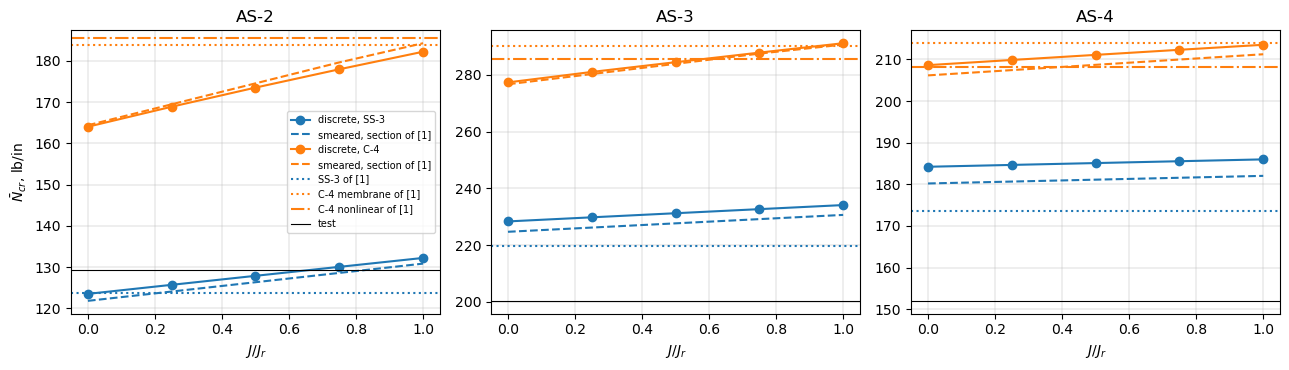

In [6]:
t0 = time.time()
RES = {}
for s in shells:
    for f in FJ:
        model = None
        for bc in ('SS', 'CC'):
            if f == 1.:
                RES[(s, bc, f)] = CONV[(s, bc, MESHES[-1])]
                continue
            model = model or build(s, MESHES[-1], f)
            ns = range(1, NS//2 + 1) if f == 0. else HARMONICS
            RES[(s, bc, f)] = (model,) + scan(model, bc, ns)
print('%.0f s' % (time.time() - t0))
rows = []
for s in shells:
    P = TABLE2[s]
    for bc in ('SS', 'CC'):
        for f in FJ:
            model, out, n = RES[(s, bc, f)]
            N, m = out[n][:2]
            ref = sm(s, f*shells[s]['Jr'], section='P', ends=bc)[0]
            row = [s, 'SS-3' if bc == 'SS' else 'C-4', f, '%.1f (%d, %d)' % (N, m, n), '%.1f' % ref,
                   '**%+.1f %%**' % pct(N, ref)]
            if bc == 'SS':
                row += ['%+.1f %%' % pct(N, P[0]), '-', '-']
            else:
                row += ['-', '%+.1f %%' % pct(N, P[1]), '%+.1f %%' % pct(N, P[2])]
            row += ['%+.1f %%' % pct(N, P[3])]
            rows.append(row)
table(['shell', 'ends', 'J/J_r', 'discrete N, lb/in (m, n)', 'smeared, same strip', 'gap', 'vs SS-3 of [1]',
       'vs C-4 membrane', 'vs C-4 nonlinear', 'vs test'], rows)


def NC(s, bc, f):
    out, n = RES[(s, bc, f)][1:]
    return out[n][0]


rows = []
for s in shells:
    P = TABLE2[s]
    row = [s]
    for bc, target in (('SS', P[0]), ('CC', P[1]), ('CC', P[2])):
        Ns = np.array([NC(s, bc, f) for f in FJ])
        row.append('%.2f' % np.interp(target, Ns, FJ) if Ns[0] <= target <= Ns[-1] else
                   ('< 0' if target < Ns[0] else '> 1'))
    rows.append(row)
table(['shell', 'J/J_r for SS-3 of [1]', 'J/J_r for C-4 membrane of [1]', 'J/J_r for C-4 nonlinear of [1]'], rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, s in zip(axes, shells):
    P = TABLE2[s]
    for bc, c in (('SS', 'C0'), ('CC', 'C1')):
        ax.plot(FJ, [NC(s, bc, f) for f in FJ], c + 'o-', label='discrete, %s' % ('SS-3' if bc == 'SS' else 'C-4'))
        ax.plot(FJ, [SM[(s, bc, f)][0] for f in FJ], c + '--', label='smeared, section of [1]')
    ax.axhline(P[0], color='C0', ls=':', label='SS-3 of [1]')
    ax.axhline(P[1], color='C1', ls=':', label='C-4 membrane of [1]')
    ax.axhline(P[2], color='C1', ls='-.', label='C-4 nonlinear of [1]')
    ax.axhline(P[3], color='k', ls='-', lw=0.8, label='test')
    ax.set_xlabel('$J/J_r$')
    ax.set_title(s)
    ax.grid(True, lw=0.3)
axes[0].set_ylabel(r'$\bar{N}_{cr}$, lb/in')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Clamped ends with the linear static pre-buckling state

`prebuckling_clamped` and `buckling_prebuckled`: both ends clamped, the end
$x = L$ shortened (the platens of the test rig), the pre-buckling state the
linear static solution, which contains the bending of the skin near the ends
that the end rings cause (the end rings of [1] hold the radial expansion).
It is the linear counterpart of the "nonlinear C-4" column of [1]; finest
mesh, `HARMONICS`, $J = J_r$ and $J = 0$.

In [7]:
t0 = time.time()
CLAMPED = {}
for s in shells:
    for f in (0., 1.):
        model = build(s, MESHES[-1], f)
        u0, P = prebuckling_clamped(model)
        out = {}
        for n in HARMONICS:
            N, X = buckling_prebuckled(model, u0, P, n, k=1)
            out[n] = (N[0], axial_nodes(model, X[:, 0]) + 1)
        n = min(out, key=lambda n: out[n][0])
        CLAMPED[(s, f)] = (out[n][0], (out[n][1], n))
print('%.0f s' % (time.time() - t0))
rows = []
for s in shells:
    P = TABLE2[s]
    for f in (0., 1.):
        N, mn = CLAMPED[(s, f)]
        rows.append([s, f, '%.1f %s' % (N, mn), '%+.1f %%' % pct(N, NC(s, 'CC', f)),
                     '%+.1f %%' % pct(N, P[1]), '%+.1f %%' % pct(N, P[2]), '%+.1f %%' % pct(N, P[3])])
table(['shell', 'J/J_r', 'N, lb/in (m, n)', 'vs membrane C-4 (discrete)', 'vs C-4 membrane of [1]',
       'vs C-4 nonlinear of [1]', 'vs test'], rows)

439 s


| shell | J/J_r | N, lb/in (m, n) | vs membrane C-4 (discrete) | vs C-4 membrane of [1] | vs C-4 nonlinear of [1] | vs test |
|---|---|---|---|---|---|---|
| AS-2 | 0.0 | 164.6 (2, 15) | +0.4 % | -10.4 % | -11.3 % | +27.4 % |
| AS-2 | 1.0 | 182.8 (2, 15) | +0.3 % | -0.5 % | -1.5 % | +41.5 % |
| AS-3 | 0.0 | 278.4 (4, 14) | +0.4 % | -4.1 % | -2.5 % | +39.0 % |
| AS-3 | 1.0 | 292.1 (4, 14) | +0.3 % | +0.6 % | +2.2 % | +45.8 % |
| AS-4 | 0.0 | 209.0 (3, 15) | +0.2 % | -2.3 % | +0.4 % | +37.5 % |
| AS-4 | 1.0 | 213.9 (3, 15) | +0.2 % | -0.0 % | +2.8 % | +40.7 % |

## Every published value against the models ($J = J_r$)

| shell | value of [1] | lb/in | smeared, section of [1] | vs [1] | discrete | vs [1] |
|---|---|---|---|---|---|---|
| AS-2 | SS-3 | 123.8 | 130.8 | +5.7 % | 132.2 | +6.8 % |
| AS-2 | C-4 membrane | 183.8 | 184.3 | +0.3 % | 182.2 | -0.9 % |
| AS-2 | C-4 nonlinear | 185.6 | - | - | 182.8 (linear static) | -1.5 % |
| AS-2 | test | 129.2 | - | - | 182.8 (C-4, linear static) | +41.5 % |
| AS-3 | SS-3 | 219.8 | 230.6 | +4.9 % | 234.1 | +6.5 % |
| AS-3 | C-4 membrane | 290.2 | 290.7 | +0.2 % | 291.2 | +0.3 % |
| AS-3 | C-4 nonlinear | 285.7 | - | - | 292.1 (linear static) | +2.2 % |
| AS-3 | test | 200.3 | - | - | 292.1 (C-4, linear static) | +45.8 % |
| AS-4 | SS-3 | 173.5 | 182.0 | +4.9 % | 186.0 | +7.2 % |
| AS-4 | C-4 membrane | 213.9 | 211.2 | -1.2 % | 213.5 | -0.2 % |
| AS-4 | C-4 nonlinear | 208.1 | - | - | 213.9 (linear static) | +2.8 % |
| AS-4 | test | 152.0 | - | - | 213.9 (C-4, linear static) | +40.7 % |

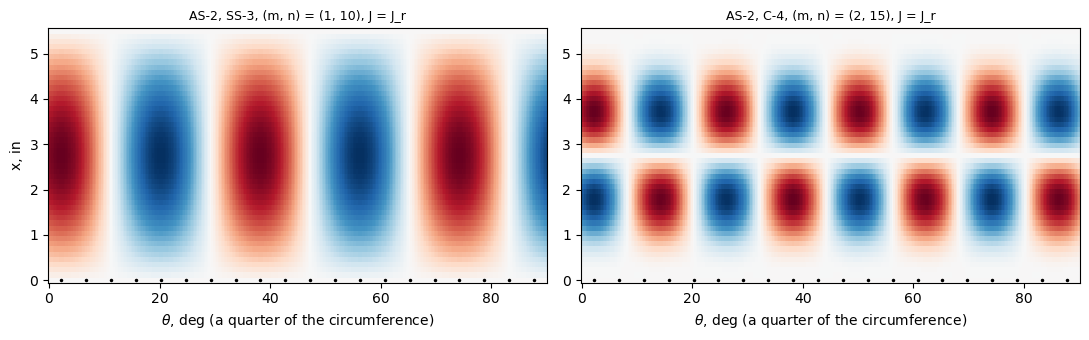

In [8]:
rows = []
for s in shells:
    P = TABLE2[s]
    Nss, Ncc, Ncl = NC(s, 'SS', 1.), NC(s, 'CC', 1.), CLAMPED[(s, 1.)][0]
    rows.append([s, 'SS-3', P[0], '%.1f' % SM[(s, 'SS', 1.)][0], '%+.1f %%' % pct(SM[(s, 'SS', 1.)][0], P[0]),
                 '%.1f' % Nss, '%+.1f %%' % pct(Nss, P[0])])
    rows.append([s, 'C-4 membrane', P[1], '%.1f' % SM[(s, 'CC', 1.)][0], '%+.1f %%' % pct(SM[(s, 'CC', 1.)][0], P[1]),
                 '%.1f' % Ncc, '%+.1f %%' % pct(Ncc, P[1])])
    rows.append([s, 'C-4 nonlinear', P[2], '-', '-', '%.1f (linear static)' % Ncl, '%+.1f %%' % pct(Ncl, P[2])])
    rows.append([s, 'test', P[3], '-', '-', '%.1f (C-4, linear static)' % Ncl, '%+.1f %%' % pct(Ncl, P[3])])
table(['shell', 'value of [1]', 'lb/in', 'smeared, section of [1]', 'vs [1]', 'discrete', 'vs [1]'], rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, bc in zip(axes, ('SS', 'CC')):
    model, out, n = RES[('AS-2', bc, 1.)]
    w = normalize_phase(model.skin_field(out[n][2], W))
    th, wf = model.full_circumference(w, n)
    sel = th <= 2*np.pi/4
    ax.pcolormesh(np.degrees(th[sel]), model.xlin, wf[:, sel]/np.abs(wf).max(), cmap='RdBu_r', vmin=-1, vmax=1,
                  shading='auto')
    pos = (np.arange(NS) + 0.5)*model.phi
    pos = pos[pos <= 2*np.pi/4]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_xlabel(r'$\theta$, deg (a quarter of the circumference)')
    ax.set_title('AS-2, %s, (m, n) = (%d, %d), J = J_r' % ('SS-3' if bc == 'SS' else 'C-4', out[n][1], n), fontsize=9)
axes[0].set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Discussion

- **Input.** The rectangle $t_s \times h_s$ from $A$ and $I$ of Table 1
  reproduces the printed eccentricity within 0.7 %, so the stringers are read
  as Singer, Arbocz and Babcock read them, up to the non-rectangular shapes
  they mention. With the section of Table 1, the clamped smeared theory (Ritz
  with the functions (A5) of [3]) and $J = J_r$ reproduces the C-4 membrane
  loads of [1] within -1.2 to +0.3 % (AS-2 184.3, AS-3 290.7, AS-4 211.2
  lb/in against 183.8, 290.2, 213.9); the $J$ that reproduces them exactly is
  0.97, 0.96 and 1.52 $J_r$. The C-4 column of [1] is therefore consistent
  with stringers that twist with the Saint-Venant constant of their
  rectangle.
- **One $J$ does not fit both columns of [1].** Equation (15) of [2] with
  $J = J_r$ is +5.7, +4.9 and +4.9 % above the SS-3 loads of [1]; with $J =
  0$ it is still +2.2 and +3.9 % above them for AS-3 and AS-4 (AS-2 -1.6 %;
  the $J$ that fits AS-2 is 0.22 $J_r$). The SS-3 column of [1] is thus lower
  than equation (15) for any non-negative $J$ by 2 to 4 % for AS-3 and AS-4,
  while the C-4 column fits $J \approx J_r$.
- **The SS-3 column and the theory of [4].** The theory that [1] names for
  its smeared analysis is that of equation (15) of [2]: the same distributed
  stringers with their eccentricity about the middle surface of the skin
  (equations (1) and (2) of [4]), the torsional stiffness $G J/d$ added once
  to the twisting term ($2 + \eta_{t1}$ in equation (6)), the Donnell-type
  equations (13), the membrane pre-buckling state (5), the classical simple
  support (3), $w = M_x = N_x = v = 0$, which is the SS-3 of [1], and integer
  wave numbers. Its equation (6) reproduces equation (15) within 0.001 % for
  every $J$ (section *The theory of the SS-3 column*), with the same modes
  (one axial half-wave, 9 or 10 circumferential waves, as [1] reports, p.
  72). The boundary conditions, the pre-buckling state and the treatment of
  the eccentricity therefore do not explain the difference, and the last
  printed digits of Table 1 change equation (6) by at most 0.15 %. With the
  stringer properties of Table 1, the theory of [4] does not give the SS-3
  column of [1]; [1] gives neither the stringer properties nor the $J$ used
  for that column, nor the program ("a variety of analytical methods", p.
  71; the stiffener properties from the measured, not always rectangular,
  shapes, p. 71). What differs is not settled by [1] and [4]; the SS-3
  values of [1] are compared, not used to choose $J$.
- **Sensitivity to $J$.** From $J = 0$ to $J = J_r$ the clamped load rises by
  11 % (AS-2), 5 % (AS-3) and 2.4 % (AS-4), the simply supported one by 7,
  2.5 and 1 %: the flat stringer of AS-2, the tallest, twists most, and the
  short clamped buckles (two to four axial half-waves, 14 to 15
  circumferential waves) twist the stringers more than the SS-3 mode of one
  half-wave. With $J = 0$ the discrete model is 2.5 to 11 % below the C-4
  loads of [1]; with $J_r$ within -0.9 to +0.3 %. The plate strip as it is, with
  18 to 53 times the twisting stiffness $G J_r$, would be far outside this
  range: a flat stringer is modelled by a blade normal to the skin only with
  the scaled $D_{66}$.
- **Discreteness gap.** The discrete model buckles in the general modes of
  the smeared theory, (1, 9 to 10) simply supported and (2 to 4, 14 to 15)
  clamped, 0.5 to 2.0 % below equation (15) or the clamped Ritz solution for
  the same plate strip and the same $J$: the gap of the Weller and Singer
  shells AS-34 and AS-35 (`weller1977_stiffened_cylinder_buckling.ipynb`, -1.2 %
  at $b/\sqrt{Rh} = 1.6$; 1.5 to 1.8 here). It grows with $J$
  for the clamped AS-2 (-1.1 to -2.0 %), where the stringers twist most.
- **Pre-buckling state.** The linear static pre-buckling state of the clamped
  shell (end rings holding the radial expansion) raises the discrete load by
  0.2 to 0.4 %; [1] finds with the nonlinear one +1.0 % (AS-2) and -1.5 and
  -2.7 % (AS-3, AS-4). The discrete model with the linear static state is
  -1.5, +2.2 and +2.8 % from the nonlinear C-4 loads of [1]: as [1]
  concludes (p. 72), the pre-buckling deformation is a small effect for
  these shells.
- **Tests.** The tests are at 0.70 to 0.73 of the nonlinear C-4 loads of [1]
  (Table 2) and 29 to 31 % below the clamped discrete model ($J = J_r$,
  linear static state); they are close to the SS-3 loads (AS-2 +4.4 %, AS-3
  and AS-4 -8.9 and -12.4 %), whereas the authors judged the end rings rigid (p. 72) and measured initial
  imperfections of about one wall thickness, with a strong pre-buckling
  growth of one axial half-wave and nine circumferential waves (p. 74), the
  shape of the simply supported mode (1, 9 to 10), not of the clamped modes
  (2 to 4, 14 to 15). Their "linearity" (test over clamped theory) is lower
  than that of the ring-stiffened shells of the same paper (0.70 to 1.12,
  Table 2).
- **The panels implementation of this case**
  (`panels/notebooks/singer1971_blade_cylinder_buckling.ipynb`: half of the
  cylinder as a `MultiDomain` assembly, curved `cylshell_clpt_sanders` skin
  panels and one `plate_clpt_gl` blade per stringer, the same strips and
  $J$) gives the same modes and agrees within 0.6 %, 0.1 to 0.2 % lower
  simply supported and 0.4 to 0.6 % lower clamped: with $J = J_r$, SS-3
  132.0, 233.9, 185.8 lb/in (here 132.2, 234.1, 186.0), C-4 membrane 181.4,
  290.0, 212.5 (here 182.2, 291.2, 213.5), linear static state 181.9, 290.9,
  212.7 (here 182.8, 292.1, 213.9); with $J = 0$, C-4 163.2, 276.1, 207.5
  (here 164.0, 277.4, 208.6). Its gaps are -1.2 to -1.5 % (SS-3) and -1.0 to
  -2.5 % (C-4). Its terms converge faster than the meshes here (at most 0.02 %
  from the second to the third level clamped, against 0.3 % here).
- **Harmonics.** The convergence runs scan every harmonic $n = 1 \ldots 40$;
  their four lowest harmonics lie between 8 and 17, and the other runs scan
  $n = 5 \ldots 25$ and $n = 40$ (local buckling of the skin between the
  stringers, never critical here).